In [19]:
from langchain_ollama import ChatOllama,OllamaEmbeddings
from typing import TypedDict,Literal
from dotenv import load_dotenv
from langgraph.graph import StateGraph,START,END
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pydantic import BaseModel,Field
from langchain_core.messages import AIMessage,HumanMessage,SystemMessage
from langchain_community.vectorstores import Chroma, FAISS
import re
import os
from dotenv import load_dotenv
load_dotenv()


llm = ChatOllama(model='qwen2.5:1.5b',temperature=0.2)
embeddings = OllamaEmbeddings(model="nomic-embed-text")


docs = (
    PyPDFLoader("documents/Company_Policies.pdf").load() + 
    PyPDFLoader("documents/Company_Profile.pdf").load() + 
    PyPDFLoader("documents/Product_and_Pricing.pdf").load()
)


chunks = RecursiveCharacterTextSplitter(
    separators=['\n\n','\n',' '],
    chunk_size=600,
    chunk_overlap=150
).split_documents(docs)


vector_store = FAISS.from_documents(documents=chunks,embedding=embeddings)
retriever = vector_store.as_retriever(search_type='mmr',search_kwargs={'k':3})


class State(TypedDict):
    question: str
    need_retrieval:bool
    docs: list[Document]
    relevant_docs: list[Document]
    context:str
    answer: str
    issup: Literal['fully_supported','partially_supported','no_support']
    retries:int
    

class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(...,description="True if external tool are needed to answer reliably, else False")

def decide_retrieval(state:State):
    decide_retrieval_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "You deside whether retrieval is needed.\n"
                "Return JSON that matches this schema: \n"
                "{{'should_retrieve':boolean}}\n\n"
                "Guidelines: \n"
                "- should_retrieve=True if answering requires specific facts,citation or info likely not in the model.\n"
                "- should_retrieve=False for general explaination,defination or reasoning that doesn't need sources.\n"
                "- If unsure, choose True."
            ),
            (
                'human',
                "Question: {question}"
            )
        ]
    )
    should_retrieve_llm = llm.with_structured_output(RetrieveDecision)
    decision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state['question'])
    )
    return {'need_retrieval':decision.should_retrieve}


def generate_direct(state:State):
    direct_generation_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "Answer the question using your general knowledge.\n"
                "Do not assume access to external documents. \n"
                "If you are unsure or the answer require specific sources, say : I dont know based on my general knowledge."
            ),
            (
                'human',
                "Question: {question}"
            )
        ]
    )
    res = llm.invoke(direct_generation_prompt.format_messages(question=state['question']))
    return {'answer':res.content}


def retrieve(state:State):
    return {'docs':retriever.invoke(state['question'])}


class RelevanceDecision(BaseModel):
    is_relevant:bool = Field(...,description="True if the document helps answer the question,else False")

def is_relevant(state:State):
    is_relevant_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "You are judging document relevance.\n"
                "Return JSON that matches this schema: {{'is_relevant':boolean}}"
                "A document is relevant if it contains information useful for answering the question."
            ),
            (
                'human',
                "Question: {question}\n\n Document: {document}"
            )
        ]
    )
    relevance_llm = llm.with_structured_output(RelevanceDecision)
    relevant_docs:list[Document] = []
    for doc in state['docs']:
        res = relevance_llm.invoke(
            is_relevant_prompt.format_messages(question=state['question'],document=doc)
        )
        if res.is_relevant:
            relevant_docs.append(doc)
    return {'relevant_docs':relevant_docs}


def generate_from_context(state:State):
    rag_genration_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "You are a business RAG assistant.\n"
                "Answer the users question using only provided context.\n"
                "If the context does not contain enough information, say : No relevant document found.\n"
                "Do not use outside knowledge.\n"
            ),
            (
                'human',
                "Question: {question} \n\n Context: {context}"
            )
        ]
    )
    context = '\n'.join(doc.page_content for doc in state['relevant_docs']).strip()
    res = llm.invoke(
        rag_genration_prompt.format_messages(question=state['question'],context=context)
    )
    return {'answer':res.content,'context':context}


def no_relevant_docs(state:State):
    return {'answer':'No relevant docs found','context':""}
    
class IsSUPDecision(BaseModel):
    issup: Literal['fully_supported','partially_supported','no_support']

def is_supported(state:State):
    issup_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "You are verifying whether the answer is supported by the context.\n"
                "Return JSON with key issup.\n"
                "issup must be one of the ['fully_supported','partially_supported','no_support'].\n"
                "How to decide issup:\n"
                "fully_supported - Every meaningful claim is supported by context and the answer does not introduce any qualitative/interpretive words that are not present in context.\n"
                "partially_supported - The core facts are supported but the answer contains any abstraction,interpretation or qualitative phrasing not explicitly stated in context.\n"
                "no_support - The key claim are not supported by context.\n"
            ),
            (
                'human',
                "Question : {question}\n"
                "Answer : {answer}\n"
                "Context: {context}\n"
            )
        ]
    )
    issup_llm = llm.with_structured_output(IsSUPDecision)
    res = issup_llm.invoke(
        issup_prompt.format_messages(question=state['question'],answer=state.get('answer',''),context=state.get('context',''))
    )
    return {'issup':res.issup}


def revise_answer(state:State):
    revise_prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',
                "You are a strict reviser.\n"
                "You must output based on the following format: \n"
                "FORMAT (quote only answer)\n"
                "- <direct quote from the context>\n"
                "- <direct qoute from the context> \n"
                "Rules: Use only the context."
            ),
            (
                'human',
                "Question : {question}\n"
                "Answer : {answer}\n"
                "Context: {context}\n"
            )
        ]
    )
    res = llm.invoke(
        revise_prompt.format_messages(question=state['question'],answer=state.get('answer',''),context=state.get('context',''))
    )
    return {'answer' : res.content,'retries':state.get('retries',0) + 1}


def accept_answer(state:State):
    return {}








def route_after_is_supported(state:State):
    MAX_RETRIES = 2 
    if state.get('issup','') == 'fully_supported':
        return 'accept_answer_node'
    if state.get('retries',0) >= MAX_RETRIES:
        return 'accept_answer_node'
    return 'revise_answer_node'

def route_after_relevance(state:State):
    if len(state['relevant_docs']):
        return 'generate_from_context_node'
    return 'no_relevant_docs_node'

def route_after_decide(state:State):
    if state['need_retrieval']:
        return 'retrieve_node'
    return 'generate_direct_node'


graph = StateGraph(State)
graph.add_node('decide_retrieval_node',decide_retrieval)
graph.add_node('generate_direct_node',generate_direct)
graph.add_node('retrieve_node',retrieve)
graph.add_node('is_relevant_node',is_relevant)
graph.add_node('generate_from_context_node',generate_from_context)
graph.add_node('no_relevant_docs_node',no_relevant_docs)
graph.add_node('is_supported_node',is_supported)
graph.add_node('revise_answer_node',revise_answer)
graph.add_node('accept_answer_node',accept_answer)

graph.add_edge(START,'decide_retrieval_node')
graph.add_conditional_edges(
    'decide_retrieval_node',
    route_after_decide,
    {
        'generate_direct_node':'generate_direct_node',
        'retrieve_node':'retrieve_node'
    }
)
graph.add_edge('retrieve_node','is_relevant_node')
graph.add_conditional_edges(
    'is_relevant_node',
    route_after_relevance,
    {
        'generate_from_context_node':'generate_from_context_node',
        'no_relevant_docs_node':'no_relevant_docs_node'
    }
)
graph.add_edge('generate_from_context_node','is_supported_node')
graph.add_conditional_edges(
    'is_supported_node',
    route_after_is_supported,
    {
        'accept_answer_node':'accept_answer_node',
        'revise_answer_node':'revise_answer_node'
    }
)
graph.add_edge('revise_answer_node','is_supported_node')
graph.add_edge('accept_answer_node',END)
graph.add_edge('no_relevant_docs_node',END)
graph.add_edge('generate_direct_node',END)

app = graph.compile()







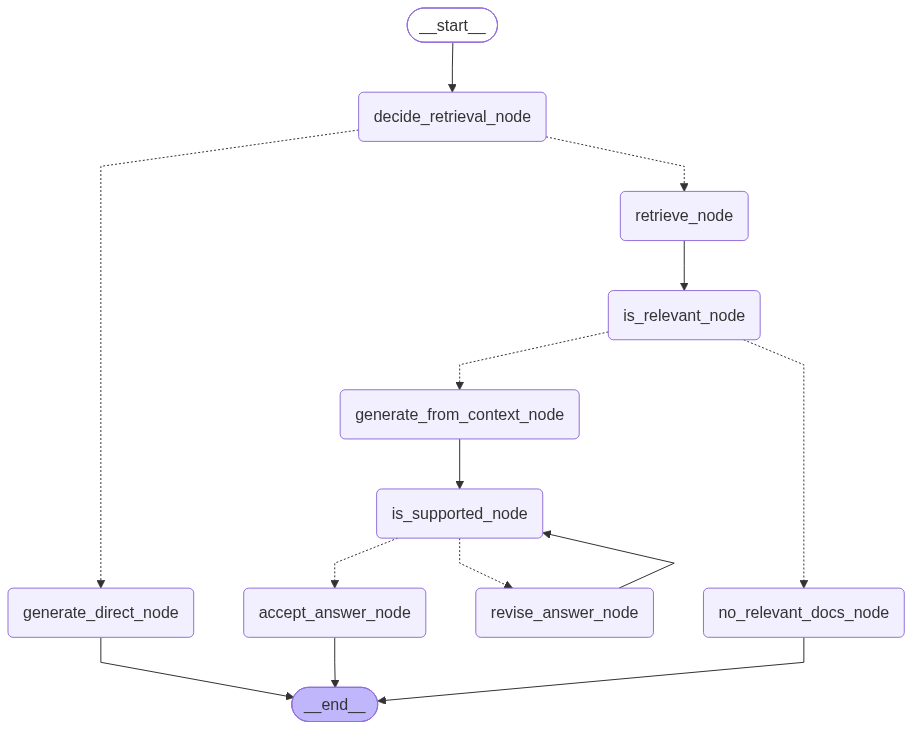

In [20]:
app

In [9]:
res = app.invoke(
    {
        'question':'what is leave policy for nexa ai comapany',
        'need_retrieval':False,
        'docs':[],
        'relevant_docs':[],
        'answer':''
    }
)

print(res)

{'question': 'what is leave policy for nexa ai comapany', 'need_retrieval': True, 'docs': [Document(id='aac6af46-a2f0-4f6d-a35b-2dbcf00ccf51', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:07:17+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:07:17+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': 'documents/Company_Policies.pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}, page_content='NexaAI Solutions – Company Policies\nHR Policies\nNexaAI is committed to maintaining a fair, inclusive, and performance-driven workplace.\nAll employment decisions are made without discrimination.\n\x7f\nEqual opportunity employer\n\x7f\nBi-annual performance reviews\n\x7f\nClear career progression framework\n\x7f\nStrict anti-harassment policy\nLeave Policy\nEmployees are encouraged to maintain a healthy work-life balance.\n\x7f\nAnnual Leave: 18 work

In [8]:
res = app.invoke(
    {
        'question':'what is refund policy of nexa ai',
        'need_retrieval':False,
        'docs':[],
        'relevant_docs':[],
        'answer':''
    }
)

print(res)

{'question': 'what is refund policy of nexa ai', 'need_retrieval': True, 'docs': [Document(id='171d84fd-73b6-4595-9877-0a91618f2d2f', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:10:37+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:10:37+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': 'documents/Product_and_Pricing.pdf', 'total_pages': 4, 'page': 0, 'page_label': '1'}, page_content='NexaAI Solutions – Products & Pricing\nProduct Portfolio Overview\nNexaAI offers a modular suite of enterprise AI products designed to help organizations manage\nknowledge, analyze business data, automate customer interactions, and enforce AI governance.\nEach product can be used independently or deployed as part of an integrated AI platform.\nNexaChat – Internal Knowledge Assistant\nNexaChat is an AI-powered internal assistant that allows employees to query

In [22]:

res = app.invoke(
    {
        'question':'what is nexa ai work culture and their leave structure',
        'need_retrieval':False,
        'docs':[],
        'relevant_docs':[],
        'answer':''
    }
)

print(res)



{'question': 'what is nexa ai work culture and their leave structure', 'need_retrieval': True, 'docs': [Document(id='71505005-342c-4f32-967e-b059071f28f0', metadata={'producer': 'ReportLab PDF Library - www.reportlab.com', 'creator': '(unspecified)', 'creationdate': '2026-02-14T13:10:37+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-02-14T13:10:37+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': 'documents/Product_and_Pricing.pdf', 'total_pages': 4, 'page': 0, 'page_label': '1'}, page_content='NexaAI Solutions – Products & Pricing\nProduct Portfolio Overview\nNexaAI offers a modular suite of enterprise AI products designed to help organizations manage\nknowledge, analyze business data, automate customer interactions, and enforce AI governance.\nEach product can be used independently or deployed as part of an integrated AI platform.\nNexaChat – Internal Knowledge Assistant\nNexaChat is an AI-powered internal assistant that all